# Tutorial: Finding disease-associated cell neighborhoods with scEPS

[scEPS](https://github.com/Genentech/sceps) (single-cell Expression exPlainability
Statistics) combines GWAS statistics with a multi-donor single-cell atlas to answer one
question: **in which cell neighborhoods does variation in disease-gene expression explain
variation in the disease phenotype across donors?**

A *cell neighborhood* is a local region of the k-NN graph, anchored on a single cell. In
each neighborhood, scEPS decomposes the variance of the donor-level phenotype into the part
attributable to GWAS genes, the part attributable to a set of **mean-expression-matched
control genes**, and the part attributable to all remaining genes. This gives, per
neighborhood:

$$
d = \omega^2_{gwas} - \omega^2_{ctrl}
$$

where $\omega^2_{gwas}$ is the phenotypic variance explained *per GWAS gene* and
$\omega^2_{ctrl}$ the same quantity per control gene. The control set matters: highly
expressed genes simply have more expression variance to offer, so comparing GWAS genes
against expression-matched controls is what makes $d$ interpretable. A positive,
significant $d$ says the neighborhood's disease-gene expression tracks the phenotype more
closely than chance expression variation of comparable magnitude would.

The method is described in the [preprint](https://www.medrxiv.org/content/10.64898/2026.06.26.26356714v1);
results for the diseases in the paper can be browsed in the
[result explorer](https://scepsresultexplorer.streamlit.app/).

## Overview

We run scEPS on cellink's dummy [OneK1K](https://onek1k.org/) dataset (125,913 PBMCs from
300 donors, with matching genotypes; we use 100 of the donors) for **rheumatoid arthritis (RA)**, an immune-mediated
disease for which PBMCs are the relevant tissue.

OneK1K is a healthy population cohort, so it carries no RA case/control status to
decompose. The scEPS paper handles exactly this situation by using a **polygenic risk score
as the phenotype**, and we follow that design: the phenotype is an RA PRS computed from the
donors' own genotypes, and the GWAS genes come from an RA GWAS.

`get_dummy_onek1k()` is a 0.4 GB download that carries everything the tutorial needs:
expression counts, a batch-harmonized embedding, donor age and sex, and 0/1/2 genotype
dosages. Its genotypes are deliberately thin (full chromosome 22 plus a 0.1% sample of
chromosomes 1-21) so the PRS below is a demonstration of the mechanics rather than a risk
estimate. `get_onek1k()` returns the full cohort if you need the real thing, at roughly
20 GB.

To keep the runtime manageable the tutorial also subsamples to 5,000 cells and a quarter of
their cell neighborhoods, and computes MAGMA's gene statistics from the HapMap3 SNPs only.
Every parameter is a variable in the setup cell.

## Contents

scEPS ships as four command-line tools, one per step. Getting to them takes three
preparation steps, which build the three inputs scEPS needs. They are the bulk of
this notebook.

**If you already have gene-level GWAS statistics, a donor-level phenotype and a harmonized
`.h5ad`, skip straight to [Step 1](#step-1-sceps-statistics-per-cell-neighborhood).** The
Step 0 sections exist to produce exactly those three things, and they are dominated by
downloads rather than by anything scEPS-specific.

| | Section | Tool | Produces |
| --- | --- | --- | --- |
| | [Setup](#setup) | | parameters, and where the data goes |
| prep | [Step 0a: gene-level GWAS statistics](#step-0a-gene-level-gwas-statistics) | MAGMA | `GENE` and `ZSTAT` per gene |
| prep | [Step 0b: the RA polygenic risk score](#step-0b-the-ra-polygenic-risk-score) | numpy | `ra_prs`, one value per donor |
| prep | [Step 0c: prepare the single-cell data](#step-0c-prepare-the-single-cell-data) | scanpy | an `.h5ad` with a batch-harmonized k-NN graph |
| scEPS | [Step 1: per-neighborhood statistics](#step-1-sceps-statistics-per-cell-neighborhood) | `sceps` | $d$ and the $\omega^2$ components per cell neighborhood |
| scEPS | [Step 2: neighborhood blocks](#step-2-approximately-independent-neighborhood-blocks) | `sceps-cluster-neighborhood` | approximately independent blocks, for the block bootstrap |
| scEPS | [Step 3: aggregate to cell types](#step-3-aggregate-to-cell-types) | `sceps-aggregate` | mean $d$ per cell type, with standard errors |
| scEPS | [Step 4: correlate with expression](#step-4-correlate-d-with-gene-expression) | `sceps-corr` | genes whose expression tracks $d$ |
| | [Summary](#summary-and-what-changes-for-a-real-study) | | the four commands, and a checklist |

The [scEPS wiki](https://github.com/Genentech/sceps/wiki) is the reference for every option;
this tutorial covers the ones you need to get a first analysis out.

## Setup

scEPS is on PyPI and installs its own command-line tools:

```shell
pip install sceps
```

**MAGMA** is downloaded by the notebook. One Python package beyond cellink's base
dependencies is also needed: `pybiomart`, which the MAGMA pipeline uses to map Entrez gene
IDs to the Ensembl IDs the single-cell data uses.

```shell
pip install pybiomart
```

```{important}
Everything this notebook writes goes under `WORK_DIR`, which defaults to `work/` beside this
notebook. That is the 0.4 GB dataset, the GWAS summary statistics, the MAGMA reference panel
and output, and the scEPS results. Budget ~10 GB, most of it the MAGMA reference panel.
To keep the data off the repository's filesystem, make `work` a
symlink to a scratch directory:

    ln -s /path/to/scratch/sceps_work work

Paths stay relative to `work/` throughout, so nothing below depends on where that points.
`SCEPS_TUTORIAL_WORKDIR` overrides it if you would rather set a path directly.
```

In [1]:
import logging
import os
import warnings

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
logging.getLogger("cellink").setLevel(logging.ERROR)

import gzip
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

from cellink.resources import (
    get_1000genomes_hapmap3,
    get_dummy_onek1k,
    get_gwas_catalog_study_summary_stats,
    get_pgs_catalog_score,
    get_pgs_catalog_score_file,
)
from cellink.tl.external import run_magma_pipeline

sc.settings.verbosity = 1

# ---------------------------------------------------------------------------
# Everything you might want to change lives here.
# ---------------------------------------------------------------------------
SEED = 0

WORK_DIR = Path(os.environ.get("SCEPS_TUTORIAL_WORKDIR", "work"))
WORK_DIR.mkdir(parents=True, exist_ok=True)

# --- Step 0a: the RA GWAS. European-only, matching OneK1K's ancestry.
RA_GWAS = "GCST90132223"  # Ishigaki 2022, RA: 22,350 cases / 74,823 controls
RA_GWAS_N = 22_350 + 74_823
GWAS_BUILD = "GRCh37"
MAGMA_WINDOW = (10, 10)

# --- Step 0b: the PRS. Privé 2022, LDpred2 on UK Biobank, 95,083 variants, European.
RA_PGS_ID = "PGS002088"
# The dummy OneK1K genotypes are GRCh38. Determined empirically, not assumed: the score's
# harmonized GRCh38 positions match 1,647 of its variants against these genotypes, the
# GRCh37 ones only 10. The cell below re-checks and fails loudly if too few match.
GENO_BUILD = "GRCh38"
MIN_SCORE_VARIANTS = 500  # a build mismatch drops this to ~10

# --- Step 0c: how much of the atlas to keep. scEPS needs at least 20 donors, the regression
# has one row per donor *pair* (100 donors: 4,950 rows), and every neighborhood must reach a
# third of the donors (--min-frac-donor), so cost grows quickly with donors: we use 100 of 300.
N_DONORS = 100
N_TOP_CELLTYPES = 6  # most abundant cell types, so Step 3 has enough per type
N_CELLS = 5_000  # cells kept, spread across the N_DONORS donors
N_NEIGHBORS = 15

# --- Step 1: the phenotype and the donor-level covariates to adjust for.
PHENO = "ra_prs"
# Covariates, following the manuscript: donor age and sex, plus the local cell proportion
# that scEPS computes per neighborhood.
COVAR = "age,sex,sceps.prop_cells_local"
# Fraction of cell neighborhoods to analyze. scEPS keeps each one independently with this
# probability, so ~0.25 x N_CELLS = 1,250 neighborhoods, drawn from across the whole object.
# At 1-3 s each that is most of an hour on one core, so Step 1 runs N_JOBS processes in
# parallel, each on its share of the cells; a real run uses 1.0.
SAMPLE_FRAC = 0.25
N_JOBS = min(8, os.cpu_count())
# Cell types with fewer analyzed neighborhoods than this are dropped from Step 3's summary:
# too few neighborhoods span too few bootstrap blocks, which collapses the standard error.
MIN_NBHD_PER_CELLTYPE = 25

# Colour scale for the d UMAP, symmetric about zero.
D_COLOR_LIMIT = 0.006

# --- Step 2 / Step 4
N_KMEANS_CLUSTERS = 20  # approximately independent blocks (default 50 assumes more cells)
MIN_NUM_NONZERO = 50  # a gene must be expressed in this many analyzed neighborhoods

# --- Paths. Nothing is written inside the repository.
DATA_HOME = WORK_DIR / "cellink_data"
DATA_HOME.mkdir(exist_ok=True)
ADATA_PATH = WORK_DIR / "sceps_input.h5ad"
OUT_DIR = WORK_DIR / "sceps_out"
OUT_DIR.mkdir(exist_ok=True)

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
print("WORK_DIR:", WORK_DIR)

WORK_DIR: work


Confirm the scEPS command-line tools are available:

In [2]:
!sceps --help | head -8

usage: sceps [-h] [--adata ADATA] [--cell-type-col CELL_TYPE_COL]
             [--focal-cell-type FOCAL_CELL_TYPE] [--gene-id-col GENE_ID_COL]
             [--cell-id-col CELL_ID_COL] [--donor-id-col DONOR_ID_COL]
             [--pheno-file PHENO_FILE] [--batch-key BATCH_KEY]
             [--gene-list GENE_LIST] [--control-gene-list CONTROL_GENE_LIST]
             [--focal-cells FOCAL_CELLS] [--total-num-job TOTAL_NUM_JOB]
             [--job-idx JOB_IDX] [--start-idx START_IDX] [--stop-idx STOP_IDX]
             [--min-expr-var-thres MIN_EXPR_VAR_THRES]


## Step 0a. Gene-level GWAS statistics

scEPS needs to know which genes are implicated by the GWAS, and how strongly. It takes this
as a whitespace-delimited text file with two columns it actually reads:

```text
GENE       ZSTAT
```

`GENE` must use the **same identifiers as the single-cell data**, Ensembl IDs here, since
that is what OneK1K's `var_names` are. `ZSTAT` is the gene-level association
statistic. Everything else in the file is ignored, so MAGMA's output can be passed straight
through.

[MAGMA](https://cncr.nl/research/magma/) produces this in two steps: map SNPs to genes
within a window, then aggregate SNP-level p-values per gene. cellink's
`run_magma_pipeline` wraps both, downloading the 1000 Genomes EUR reference panel and the
gene location file for you.

First the MAGMA binary itself, which is not pip-installable:

In [3]:
import io
import platform
import stat
import zipfile

import requests

MAGMA_DIR = WORK_DIR / "magma"
MAGMA_BIN = MAGMA_DIR / "magma"

if not MAGMA_BIN.exists():
    share_ids = {"Linux": "lxDgt2dNdNr6DYt", "Darwin": "1M1d9vHtVidEwvU"}
    system = platform.system()
    if system not in share_ids:
        raise RuntimeError(f"No known MAGMA v1.10 build for {system!r}; see https://cncr.nl/research/magma/")
    url = f"https://vu.data.surf.nl/public.php/dav/files/{share_ids[system]}"
    MAGMA_DIR.mkdir(exist_ok=True)
    with zipfile.ZipFile(io.BytesIO(requests.get(url, timeout=600).content)) as zf:
        zf.extractall(MAGMA_DIR)
    MAGMA_BIN.chmod(MAGMA_BIN.stat().st_mode | stat.S_IEXEC)

print(subprocess.run([str(MAGMA_BIN), "--version"], capture_output=True, text=True).stdout.strip()[:200])

MAGMA version: v1.10 (linux/s)


`get_gwas_catalog_study_summary_stats` fetches harmonized summary statistics from the GWAS
Catalog; `run_magma_pipeline` turns them into gene-level statistics. We use
[GCST90132223](https://www.ebi.ac.uk/gwas/studies/GCST90132223), Ishigaki et al. (2022),
22,350 cases and 74,823 controls, European-only, which matches OneK1K's ancestry.

SNPs are assigned to genes within 10 kb either side, the default of the scEPS wiki's MAGMA
script (cellink's own default is 35 kb upstream, 10 kb downstream). `gene_id_type="ensembl"`
converts MAGMA's Entrez IDs to Ensembl IDs on the primary assembly, so they line up with
OneK1K's `var_names`.

MAGMA's run time grows with the number of SNPs per gene, and the largest genes hold over
20,000 of the GWAS's 13 million variants. To keep the tutorial short we pass only the ~1.2
million HapMap3 SNPs, the SNP set of LD score regression; a real analysis passes every SNP.
The result is cached on disk and skipped on re-runs.

In [4]:
# MAGMA needs SNP, CHR, BP and P; map the GWAS Catalog's harmonized names onto them.
# The rsID column is called `variant_id` in these files. Check the column names of your
# own sumstats, since the Catalog's harmonized schema is not identical across studies.
COL_MAPPING = {
    "variant_id": "SNP",
    "chromosome": "CHR",
    "base_pair_location": "BP",
    "p_value": "P",
}

MAGMA_PREFIX = WORK_DIR / "magma_RA"
magma_genes = Path(f"{MAGMA_PREFIX}.genes.out")

if magma_genes.exists():
    print(f"{magma_genes.name} already exists, skipping")
else:
    gwas = get_gwas_catalog_study_summary_stats(
        RA_GWAS, genome_build=GWAS_BUILD, dest=DATA_HOME / f"{RA_GWAS}_summary_stats.tsv.gz"
    )
    print(f"{gwas.shape[0]:,} variants")
    # HapMap3 SNPs only, to keep MAGMA fast; a real analysis keeps every SNP
    hapmap3 = set(pd.read_csv(get_1000genomes_hapmap3(data_home=DATA_HOME), header=None)[0])
    gwas = gwas[gwas["variant_id"].isin(hapmap3)]
    print(f"{gwas.shape[0]:,} of them HapMap3 SNPs")

    magma_genes = run_magma_pipeline(
        gwas,
        output_prefix=str(MAGMA_PREFIX),
        col_mapping=COL_MAPPING,
        n_samples=RA_GWAS_N,
        genome_build=GWAS_BUILD,
        gene_id_type="ensembl",  # match OneK1K's var_names
        window_size=MAGMA_WINDOW,
        ld_source="reference_panel",
        reference_panel="EUR",
        magma_bin=str(MAGMA_BIN),
        data_home=DATA_HOME,
        n_jobs=N_JOBS,  # MAGMA gene analysis in N_JOBS parallel batches
    )

print("gene-level statistics:", magma_genes)

[2026-11-14 22:41:14,047] INFO:root: Fetching https://www.ebi.ac.uk/gwas/rest/api/v2/studies/GCST90132223
[2026-11-14 22:41:14,380] INFO:root: User requested GRCh37, searching for a build-specific file
[2026-11-14 22:41:14,558] INFO:root: Selected file matching requested build GRCh37: GCST90132223_buildGRCh37.tsv.gz
[2026-11-14 22:41:14,559] INFO:root: Using build-specific summary statistics (build: GRCh37)
[2026-11-14 22:41:14,559] INFO:root: Downloading http://ftp.ebi.ac.uk/pub/databases/gwas/summary_statistics/GCST90132001-GCST90133000/GCST90132223/GCST90132223_buildGRCh37.tsv.gz to work/cellink_data/GCST90132223_summary_stats.tsv.gz


GCST90132223_summary_stats.tsv.gz: 100%|██████████| 324M/324M [00:55<00:00, 5.80MB/s]


13,297,690 variants
[2026-11-14 22:42:23,133] INFO:root: Downloading https://zenodo.org/records/10515792/files/hm3_no_MHC.list.txt?download=1 to work/cellink_data/1000genomes_hapmap3/hm3_no_MHC.list.txt


hm3_no_MHC.list.txt: 100%|██████████| 12.4M/12.4M [00:01<00:00, 6.28MB/s]


1,208,669 of them HapMap3 SNPs
[2026-11-14 22:42:35,039] INFO:root: Downloading https://vu.data.surf.nl/public.php/dav/files/Pj2orwuF2JYyKxq/?accept=zip to work/cellink_data/magma_references/GRCh37.zip


GRCh37.zip: 100%|██████████| 356k/356k [00:00<00:00, 2.96MB/s]


[2026-11-14 22:42:37,390] INFO:root: Downloading https://vu.data.surf.nl/public.php/dav/files/VZNByNwpD8qqINe/?accept=zip to work/cellink_data/magma_references/g1000_eur.zip


g1000_eur.zip: 100%|██████████| 512M/512M [00:04<00:00, 107MB/s]


gene-level statistics: work/magma_RA.genes.out


MAGMA's output, and the two columns scEPS reads:

In [5]:
genes = pd.read_csv(magma_genes, sep=r"\s+")
print(f"{genes.shape[0]:,} genes")
print(genes.sort_values("P").head(6)[["GENE", "CHR", "NSNPS", "ZSTAT", "P"]].to_string(index=False))

17,764 genes
           GENE  CHR  NSNPS   ZSTAT            P
ENSG00000196126    6      1 14.9330 1.000000e-50
ENSG00000204387    6      1 13.4860 9.507000e-42
ENSG00000237649    6      1  9.1413 3.086000e-20
ENSG00000232810    6     20  8.0577 3.885800e-16
ENSG00000116774    1     16  7.9223 1.165700e-15
ENSG00000030110    6     25  7.8327 2.387000e-15


## Step 0b. The RA polygenic risk score

This is the donor-level phenotype whose variance scEPS decomposes. Three ingredients: the
genotypes, a published set of PRS weights, and a dot product.

### Step 0b.1 The genotypes

`get_dummy_onek1k()` returns a `DonorData` with both modalities: `dd.C` for expression and
`dd.D` for genotypes. The genotypes come as 0/1/2 dosages, which is all a polygenic score
needs, so no VCF and no PLINK are involved. Each dosage counts copies of `a1`, the alternative allele;
variant IDs read `chrom_pos_a0_a1`.

In [6]:
dd = get_dummy_onek1k(data_home=str(DATA_HOME))
print(dd)
print("\ngenotypes:", dd.D.shape, "| dtype:", dd.D.X.dtype, "| values:", sorted(np.unique(dd.D.X[:, :500]))[:4])
print("variant annotations:", list(dd.D.var.columns)[:6])
print(dd.D.var[["chrom", "pos", "a0", "a1", "AF"]].head(3).to_string())

# Thin on purpose: full chr22 plus a 0.1% sample of chr1-21.
per_chrom = dd.D.var["chrom"].astype(str).value_counts()
print(
    f"\nchr22: {per_chrom.get('22', 0):,} variants | all other chromosomes: "
    f"{int(per_chrom.sum() - per_chrom.get('22', 0)):,}"
)
print("donor IDs match between modalities:", set(dd.C.obs["donor_id"].astype(str)) == set(dd.D.obs.index.astype(str)))

[2026-11-14 22:53:17,431] INFO:root: work/cellink_data/dummy_onek1k/dummy_onek1k_dataset.dd.h5 already exists
[2026-11-14 22:53:17,446] INFO:root: Verifying checksum
[2026-11-14 22:53:24,663] INFO:root: Loaded dummy OneK1K dataset: (300, 146939, 125913, 34830)
DonorData(n_G_obs=300, n_G_vars=146,939, n_C_obs=125,913, n_C_vars=34,830)

genotypes: (300, 146939) | dtype: float32 | values: [np.float32(0.0), np.float32(1.0), np.float32(2.0)]
variant annotations: ['AF', 'AN', 'ER2', 'IMPUTED', 'maf', 'NS']
                                         chrom     pos a0                             a1        AF
snp_id                                                                                            
2_170924_G_GCA                               2  170924  G                            GCA  0.061020
2_178356_A_C                                 2  178356  A                              C  0.459472
2_547130_C_CACTCAGCTCTGAAGACTCAGCTCTGAAG     2  547130  C  CACTCAGCTCTGAAGACTCAGCTCTGAAG  0.119308

### Step 0b.2 The PRS weights

We use [PGS002088](https://www.pgscatalog.org/score/PGS002088/), an RA score from Privé et
al. (2022), built with LDpred2 on UK Biobank, 95,083 variants, European ancestry.

The genotypes carry no rsIDs (their IDs are positional, `2_178356_A_C`), so the score has to
be matched on chromosome and position, which means the two must be in the same genome
build. PGS Catalog publishes *harmonized* files with positions lifted to a named build, so
we take the one matching the genotypes rather than the author-submitted file, whose build
may differ: `get_pgs_catalog_score_file(..., genome_build=...)` downloads exactly that file.

In [7]:
pgs_meta = get_pgs_catalog_score(RA_PGS_ID)
print(f"{pgs_meta['id']}: {pgs_meta['trait_reported']}")
print(f"  variants:        {pgs_meta['variants_number']:,}")
print(f"  submitted build: {pgs_meta['variants_genomebuild']}")
print(f"  weights:         {pgs_meta['weight_type']}")
print(
    f"  reference:       {pgs_meta['publication']['firstauthor']} " f"{pgs_meta['publication']['date_publication'][:4]}"
)

pgs_path = get_pgs_catalog_score_file(RA_PGS_ID, genome_build=GENO_BUILD, data_home=DATA_HOME, return_path=True)

keep = ("#pgs_id", "#trait_reported", "#genome_build", "#variants_number", "#weight_type", "#HmPOS_build")
with gzip.open(pgs_path, "rt") as fh:
    print("\n" + "".join(ln for ln in fh if ln.startswith(keep)))

pgs = pd.read_csv(pgs_path, sep="\t", comment="#", low_memory=False)
print(pgs[["hm_rsID", "hm_chr", "hm_pos", "effect_allele", "other_allele", "effect_weight"]].head(3).to_string(index=False))

[2026-11-14 22:53:24,927] INFO:root: Fetching https://www.pgscatalog.org/rest/score/PGS002088
PGS002088: Rheumatoid arthritis
  variants:        95,083
  submitted build: GRCh37
  weights:         beta
  reference:       Privé F 2022
[2026-11-14 22:53:25,370] INFO:root: Fetching https://www.pgscatalog.org/rest/score/PGS002088
[2026-11-14 22:53:25,575] INFO:root: Downloading https://ftp.ebi.ac.uk/pub/databases/spot/pgs/scores/PGS002088/ScoringFiles/Harmonized/PGS002088_hmPOS_GRCh38.txt.gz to work/cellink_data/PGS002088_hmPOS_GRCh38_scoring_file.txt.gz

#pgs_id=PGS002088
#trait_reported=Rheumatoid arthritis
#genome_build=GRCh37
#variants_number=95083
#weight_type=beta
#HmPOS_build=GRCh38

  hm_rsID hm_chr  hm_pos effect_allele other_allele  effect_weight
rs2840532      1 2396376             T            C   5.036556e-11
rs2645081      1 2397275             G            A   4.823935e-08
rs3001336      1 2401592             A            G   3.727476e-08


### Step 0b.3 Scoring

Match the score's variants to the genotypes on chromosome, position and both alleles,
orient each weight to the allele the dosage actually counts, and take the dot product.
`dd.D.var` names the two alleles `a0` and `a1`, with the dosage counting copies of `a1`, so
where the score's effect allele is `a0` instead, the dosage flips to `2 - dosage`.

Position alone is not enough: multi-allelic sites appear as several genotype rows at the same
position, and a score variant must land on the row carrying its own two alleles.

How many variants carry over is the number to watch: a score that overlaps almost nothing
still produces a PRS, just a meaningless one, so we assert on it rather than trusting it.

In [8]:
var = dd.D.var
chrom_pos = var["chrom"].astype(str) + ":" + var["pos"].astype(int).astype(str)
a0, a1 = var["a0"].astype(str), var["a1"].astype(str)
print(f"{int(chrom_pos.duplicated().sum()):,} genotype rows share their position with another row")

cols = np.arange(dd.D.n_vars)
lookup = pd.concat(
    [
        pd.DataFrame({"col": cols, "flip": False}, index=(chrom_pos + ":" + a1 + ":" + a0).values),
        pd.DataFrame({"col": cols, "flip": True}, index=(chrom_pos + ":" + a0 + ":" + a1).values),
    ]
)
lookup = lookup[~lookup.index.duplicated(keep=False)]

score = pgs.dropna(subset=["hm_chr", "hm_pos"])
score_pos = score["hm_chr"].astype(str) + ":" + score["hm_pos"].astype(int).astype(str)
score.index = score_pos + ":" + score["effect_allele"].astype(str) + ":" + score["other_allele"].astype(str)
score = score[~score.index.duplicated(keep=False)]
matched = score[["hm_chr", "effect_weight"]].join(lookup, how="inner")

print(
    f"{int(score_pos.isin(set(chrom_pos)).sum()):,} of {pgs.shape[0]:,} score variants sit at a genotyped "
    f"position; {len(matched):,} also match both alleles"
)
print(f"  effect allele == a1: {int((~matched['flip']).sum()):,} | == a0 (dosage flipped): {int(matched['flip'].sum()):,}")
if len(matched) < MIN_SCORE_VARIANTS:
    raise ValueError(
        f"Only {len(matched)} usable variants. This usually means GENO_BUILD ({GENO_BUILD}) "
        f"is not the build of your genotypes. Try the other harmonized file."
    )

dosage = np.asarray(dd.D.X[:, matched["col"].values], dtype=float)
flip = matched["flip"].values
dosage[:, flip] = 2 - dosage[:, flip]
weights = matched["effect_weight"].values

donor_pheno = pd.DataFrame(
    {
        "donor_id": dd.D.obs.index.astype(str),
        "ra_prs": dosage @ weights,
    }
)
donor_pheno["ra_prs_z"] = (donor_pheno["ra_prs"] - donor_pheno["ra_prs"].mean()) / donor_pheno["ra_prs"].std()

on_22 = int((matched["hm_chr"].astype(str) == "22").sum())
print(f"\nPRS over {len(matched):,} variants ({on_22:,} on chr22), {donor_pheno.shape[0]} donors")
print(donor_pheno[["ra_prs", "ra_prs_z"]].describe().loc[["mean", "std", "min", "max"]])
donor_pheno.head()

6,847 genotype rows share their position with another row
1,647 of 95,083 score variants sit at a genotyped position; 1,647 also match both alleles
  effect allele == a1: 1,633 | == a0 (dosage flipped): 14

PRS over 1,647 variants (1,558 on chr22), 300 donors
            ra_prs      ra_prs_z
mean  1.079622e-07 -1.776357e-17
std   9.709171e-06  1.000000e+00
min  -2.332254e-05 -2.413234e+00
max   2.567564e-05  2.633354e+00


,donor_id,ra_prs,ra_prs_z
0,OneK1K_387,-2.885516e-06,-0.308314
1,OneK1K_809,-7.168935e-06,-0.749487
2,OneK1K_137,-3.921645e-07,-0.051511
3,OneK1K_452,9.049853e-06,0.920974
4,OneK1K_1072,-4.572947e-06,-0.482112


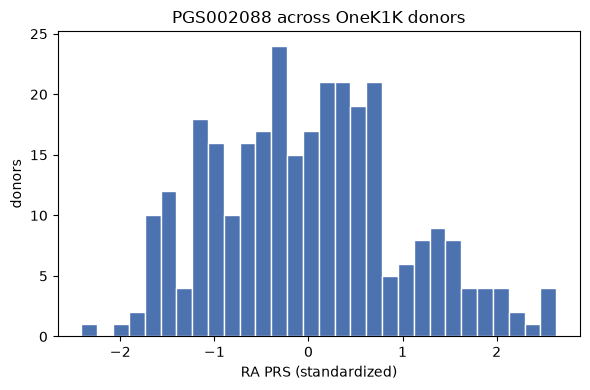

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(donor_pheno["ra_prs_z"], bins=30, color="#4C72B0", edgecolor="white")
ax.set(xlabel="RA PRS (standardized)", ylabel="donors", title=f"{RA_PGS_ID} across OneK1K donors")
plt.tight_layout()
plt.show()

## Step 0c. Prepare the single-cell data

scEPS reads one `.h5ad` file and expects the following from it:

| Requirement | Why | Here |
| --- | --- | --- |
| ≥ 20 donors with phenotype variation | the variance decomposition is *across donors* | 100 donors |
| a donor ID column in `adata.obs` | groups cells by donor | `donor_id` |
| a donor-level phenotype | the quantity whose variance is decomposed | `ra_prs` from Step 0b |
| a k-NN graph in `adata.obsp["connectivities"]` | defines the neighborhoods | built below |
| a batch-harmonized cell embedding | the graph should be built on it, and Step 2 clusters neighborhoods in it | `X_harmony`, shipped with the dataset |
| a cell type column in `adata.obs` | Step 3 aggregates by it | `celltype` |

Gene and cell identifiers can be left to the index: with `--gene-id-col` / `--cell-id-col`
unset, scEPS uses `adata.var.index` / `adata.obs.index` and calls them `sceps.gene_index` /
`sceps.cell_index`. We rely on that throughout, so the four steps agree on identifiers
without extra bookkeeping.

### Step 0c.1 The full preprocessing recipe (explained)

scEPS assumes QC'd, batch-harmonized data. The scEPS repository ships an example recipe in
`misc/preprocess_scdata.py`, reproduced below; it is *not* executed here because OneK1K
already comes QC'd with a harmonized embedding, and QC thresholds are dataset-specific.

In [10]:
# --- misc/preprocess_scdata.py, for reference (not executed) ---------------
"""
import numpy as np
import scanpy as sc
import scanpy.external as sce

adata = sc.read_h5ad("<raw counts>.h5ad")

# Drop batches with too few cells
batch_nm = "<batch column>"
counts = adata.obs[batch_nm].value_counts()
adata = adata[adata.obs[batch_nm].isin(counts[counts >= 3].index)]

# QC and log-normalization
sc.pp.filter_genes(adata, min_cells=3)
sc.pp.filter_cells(adata, min_genes=200)
adata.var["mt"] = adata.var_names.str.startswith("MT-")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)
adata = adata[adata.obs.pct_counts_mt < 5, :]
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# Batch-harmonized embedding and k-NN graph
sc.pp.highly_variable_genes(adata, n_top_genes=2000, inplace=True)
sc.pp.pca(adata, use_highly_variable=True)
sce.pp.harmony_integrate(adata, batch_nm, basis="X_pca", max_iter_harmony=50)
sc.pp.neighbors(adata, use_rep="X_pca_harmony")
sc.tl.umap(adata)
adata.write_h5ad("harmonized.h5ad")

# Optionally also save a copy with batch regressed out of the expression itself,
# and a copy with no adata.X at all (Steps 2 and 3 only need the graph, so the
# small file keeps their memory use down).
sc.pp.regress_out(adata, keys=[batch_nm])
adata.X = adata.X.astype(np.float32)
adata.write_h5ad("harmonized.regressout.h5ad")

del adata.X
adata.write_h5ad("harmonized.noX.h5ad")
"""

'\nimport numpy as np\nimport scanpy as sc\nimport scanpy.external as sce\n\nadata = sc.read_h5ad("<raw counts>.h5ad")\n\n# Drop batches with too few cells\nbatch_nm = "<batch column>"\ncounts = adata.obs[batch_nm].value_counts()\nadata = adata[adata.obs[batch_nm].isin(counts[counts >= 3].index)]\n\n# QC and log-normalization\nsc.pp.filter_genes(adata, min_cells=3)\nsc.pp.filter_cells(adata, min_genes=200)\nadata.var["mt"] = adata.var_names.str.startswith("MT-")\nsc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)\nadata = adata[adata.obs.pct_counts_mt < 5, :]\nsc.pp.normalize_total(adata, target_sum=1e4)\nsc.pp.log1p(adata)\n\n# Batch-harmonized embedding and k-NN graph\nsc.pp.highly_variable_genes(adata, n_top_genes=2000, inplace=True)\nsc.pp.pca(adata, use_highly_variable=True)\nsce.pp.harmony_integrate(adata, batch_nm, basis="X_pca", max_iter_harmony=50)\nsc.pp.neighbors(adata, use_rep="X_pca_harmony")\nsc.tl.umap(adata)\nadata.write_h5ad(

```{tip}
That recipe writes three files on purpose. Step 1 needs the expression matrix, but Steps 2
and 3 only need the graph and `obs`, so pointing them at the `.noX` copy is the easiest way
to cut memory on a large atlas.
```

What the expression modality, `dd.C`, holds:

In [11]:
celltype_key = "predicted.celltype.l2"
obs = dd.C.obs

print(dd.C)
print(
    "\ndonors:",
    obs["donor_id"].nunique(),
    "| batches:",
    obs["pool_number"].nunique(),
    "| cell types:",
    obs[celltype_key].nunique(),
)
print("disease label:", obs["disease"].value_counts().to_dict())

AnnData object with n_obs × n_vars = 125913 × 34830
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'donor_id', 'pool_number', 'predicted.celltype.l2', 'predicted.celltype.l2.score', 'age', 'organism_ontology_term_id', 'tissue_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'vst.mean', 'vst.variance', 'vst.variance.expected', 'vst.variance.standardized', 'vst.variable', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'start', 'end', 'chrom', 'strand'
    uns: 'cell_type_ontology_term_id_colors', 'citation', 'default_embedding', 'schema_reference', 'schema_

`dd.C` and `dd.D` use the same donor IDs, so the score computed above joins onto the cells
directly, with no identifier reconciliation needed.

### Step 0c.2 Subsampling

scEPS analyzes one neighborhood per cell, so all cells would take far too long. We keep 100 of
the 300 donors: the method needs at least 20, the regression already has one row per donor
*pair*, and each neighborhood has to grow until it covers a third of the donors. Within them we
subsample cells, keeping only the most abundant cell types so Step 3 has enough neighborhoods
per type to aggregate over.

In [12]:
top_celltypes = obs[celltype_key].value_counts().head(N_TOP_CELLTYPES)
print(top_celltypes)

donors = rng.choice(np.sort(obs["donor_id"].astype(str).unique()), size=N_DONORS, replace=False)
eligible = np.where(obs[celltype_key].isin(top_celltypes.index) & obs["donor_id"].astype(str).isin(donors))[0]
keep = np.sort(rng.choice(eligible, size=min(N_CELLS, eligible.size), replace=False))
print(f"\n{eligible.size:,} eligible cells -> keeping {keep.size:,}")

adata = dd.C[keep].copy()

# A clean column name, so Step 3's output file is not called
# "step3.predicted.celltype.l2.sceps.omega.celltype.txt".
adata.obs["celltype"] = adata.obs[celltype_key].astype(str)

cells_per_donor = adata.obs["donor_id"].value_counts()
cells_per_donor = cells_per_donor[cells_per_donor > 0]
print(f"{adata.n_obs:,} cells x {adata.n_vars:,} genes, {cells_per_donor.size} donors")
print(
    f"cells per donor: min {cells_per_donor.min()}, median {int(cells_per_donor.median())}, max {cells_per_donor.max()}"
)

predicted.celltype.l2
CD4 TCM      28693
CD4 Naive    26230
NK           17110
CD8 TEM      16270
B naive       6180
CD8 Naive     4859
Name: count, dtype: int64

33,142 eligible cells -> keeping 5,000
5,000 cells x 34,830 genes, 100 donors
cells per donor: min 30, median 49, max 71


`X` in this file is raw counts, so normalize and log-transform it, drop genes expressed in
almost no cells, and build the k-NN graph **on `X_harmony`**, the embedding the dataset was
published with.

We do *not* subset to highly variable genes. scEPS needs the full gene set:
its third variance component is "all remaining genes", and control genes are sampled across
the whole expression range.

In [13]:
print("X max before normalization:", float(adata.X.max()), "(raw counts)" if float(adata.X.max()) > 50 else "")

if float(adata.X.max()) > 50:
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)

sc.pp.filter_genes(adata, min_cells=10)

# The graph defines the neighborhoods, so it must be built on the batch-harmonized
# embedding. Otherwise neighborhoods track batch rather than biology.
sc.pp.neighbors(adata, n_neighbors=N_NEIGHBORS, use_rep="X_harmony")

print(f"\n{adata.n_obs:,} cells x {adata.n_vars:,} genes retained")
print("k-NN graph:", adata.obsp["connectivities"].shape)
print("embeddings:", list(adata.obsm.keys()))

X max before normalization: 1097.0 (raw counts)

5,000 cells x 12,580 genes retained
k-NN graph: (5000, 5000)
embeddings: ['X_azimuth_spca', 'X_azimuth_umap', 'X_harmony', 'X_pca', 'X_umap']


### Step 0c.3 The phenotype and covariates

Attach the phenotype. scEPS wants it as a per-cell column that is constant within donor.

Covariates named in `--covar` are regressed out of the phenotype up front, so they must be
**donor-level**. `age` and `sex` already are, straight from the OneK1K metadata. The one
exception is `sceps.prop_cells_local`, which scEPS computes per neighborhood and which is
worth including so a neighborhood's cell abundance does not masquerade as a phenotype
effect. Together these are the covariates the scEPS manuscript adjusts for.

In [14]:
prs_by_donor = donor_pheno.set_index("donor_id")["ra_prs_z"]
adata.obs["ra_prs"] = adata.obs["donor_id"].astype(str).map(prs_by_donor).astype(float)
adata.obs["age"] = adata.obs["age"].astype(float)
# cellink encodes `sex` as 1 = male, 0 = female, so it passes through as a numeric covariate.
adata.obs["sex"] = adata.obs["sex"].astype(float)

# Donors with a missing phenotype would be dropped by scEPS anyway; do it explicitly.
adata = adata[adata.obs["ra_prs"].notna()].copy()

per_donor = adata.obs.groupby("donor_id", observed=True)[["ra_prs", "age", "sex"]].first()
print(f"{per_donor.shape[0]} donors with a phenotype")
print(
    f"{PHENO}: mean {per_donor['ra_prs'].mean():.3f}, sd {per_donor['ra_prs'].std():.3f}, "
    f"range {per_donor['ra_prs'].min():.2f} to {per_donor['ra_prs'].max():.2f}"
)
print(f"age: mean {per_donor['age'].mean():.1f}, range {per_donor['age'].min():.0f}-{per_donor['age'].max():.0f}")
print("sex:", per_donor["sex"].value_counts().to_dict())

100 donors with a phenotype
ra_prs: mean 0.010, sd 0.942, range -2.02 to 2.15
age: mean 63.4, range 19-91
sex: {0.0: 53, 1.0: 47}


In [15]:
adata.write_h5ad(ADATA_PATH)
print(f"{ADATA_PATH} ({ADATA_PATH.stat().st_size / 1e6:.0f} MB)")
print(adata)

... storing 'donor_id' as categorical
... storing 'celltype' as categorical
... storing 'chrom' as categorical
... storing 'strand' as categorical


work/sceps_input.h5ad (51 MB)
AnnData object with n_obs × n_vars = 5000 × 12580
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'donor_id', 'pool_number', 'predicted.celltype.l2', 'predicted.celltype.l2.score', 'age', 'organism_ontology_term_id', 'tissue_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'cell_type_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'development_stage_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'organism', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'celltype', 'ra_prs'
    var: 'vst.mean', 'vst.variance', 'vst.variance.expected', 'vst.variance.standardized', 'vst.variable', 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'start', 'end', 'chrom', 'strand', 'n_cells'
    uns: 'cell_type_ontology_term_id_colors', 

## Step 1. scEPS statistics per cell neighborhood

This is the step that does the work. For each cell in turn, `sceps`:

1. grows a neighborhood around that cell by a random walk on the k-NN graph, expanding until
   it holds enough cells (`--min-num-cell`) and enough donors (`--min-num-donor`,
   `--min-frac-donor`);
2. builds the donor × gene expression matrix for that neighborhood;
3. selects the GWAS genes, and samples control genes matched on mean expression;
4. decomposes the phenotypic variance into GWAS / control / remaining components by method
   of moments, and bootstraps standard errors.

The flags below are the recommended defaults from the wiki:

| Flag | Why |
| --- | --- |
| `--auto-gene-selection` | select GWAS genes by MAGMA FDR rather than a fixed top-N |
| `--scale-pheno` | standardize the phenotype globally before decomposing |
| `--scale-pheno-neighborhood` | standardize again within each neighborhood |
| `--covar` | regress out donor covariates; include `sceps.prop_cells_local` |

### Step 1.1 Sizing the run

Cost scales with the number of neighborhoods (one per cell), the number of donors, and the
number of genes. Analyzing all 5,000 kept cells would take about two hours on one core, so we down-sample
with `--sample-frac`: scEPS keeps each neighborhood independently with that probability, so
the ones analyzed are spread across the whole object.

```{tip}
Prefer `--sample-frac` over `--start-idx` / `--stop-idx` for down-sampling. The index bounds
take a *contiguous* slice, and rows in an `.h5ad` are usually grouped by donor or batch, so
a slice can concentrate every analyzed neighborhood in a handful of donors. Reserve the
index bounds for splitting a full run across parallel jobs, where every slice gets done.
```

```{important}
Every scEPS step exits without recomputing if its output file already exists. That is what
makes a parallel run resumable, but it also means re-running this notebook after changing
`PHENO`, `SAMPLE_FRAC` or any other setting would silently reuse the previous results. The cell
below clears them first. Set `RESUME = True` to keep them and pick up an interrupted run
instead, or pass `--force-rerun` to an individual `sceps` call.
```

In [16]:
RESUME = False

if RESUME:
    print("RESUME=True: keeping any existing output")
else:
    stale = sorted(p for p in OUT_DIR.glob("step*") if p.is_file())
    for p in stale:
        p.unlink()
    print(f"cleared {len(stale)} previous output file(s)" if stale else "no previous output to clear")

no previous output to clear


### Step 1.2 The run

Apart from the one-off MAGMA run, this is the long cell. It runs `N_JOBS` `sceps` processes at once, each on its share of the cells (`--total-num-job` / `--job-idx`, see Step 1.4), and prints the log of the first one.

In [17]:
step1_cmd = [
    "sceps",
    "--adata", str(ADATA_PATH),
    "--donor-id-col", "donor_id",
    "--gene-list", str(magma_genes),
    "--auto-gene-selection",
    "--pheno", PHENO,
    "--scale-pheno",
    "--scale-pheno-neighborhood",
    "--covar", COVAR,
    "--sample-frac", str(SAMPLE_FRAC),
    "--total-num-job", str(N_JOBS),
    "--out", f"{OUT_DIR}/step1",
]  # fmt: skip
# one core per process: one numpy thread each
env = {**os.environ, "OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "MKL_NUM_THREADS": "1"}
jobs = [
    subprocess.Popen(
        [*step1_cmd, "--job-idx", str(i)], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env
    )
    for i in range(N_JOBS)
]
logs = [job.communicate()[0] for job in jobs]
print(logs[0])
assert all(job.returncode == 0 for job in jobs), [job.returncode for job in jobs]

2026-11-14 22:55:54,413 - INFO - Loaded 5000 cells for 100 samples
2026-11-14 22:55:55,587 - INFO - 10429 genes after intersecting gene list
2026-11-14 22:55:55,667 - INFO - Selected 672 genes for analysis

100%|██████████| 625/625 [07:33<00:00,  1.38it/s]



The log's `Selected 672 genes` is `--auto-gene-selection` at work: scEPS keeps the genes at
MAGMA FDR < 5% among those present in the data, capped at `--max-num-gwas-genes` (2,000) and
floored at `--min-num-gwas-genes` (500). Here 672 genes pass, within those bounds, so all
of them are used. Each neighborhood then drops genes without enough expression variance,
which is why Step 1's `NUM_GENE_GWAS` is smaller still.

Each process writes a file named after the index range it scanned, as in
`step1.<start>-<stop>.sceps.omega.txt.gz`, with a `.log` file recording every argument used. Note that the range is the range
*scanned*, not the number analyzed: `--sample-frac` thins within it.

The `.log` file is a plain record of the arguments the run used, worth keeping alongside
results:

In [18]:
log = pd.read_table(next(OUT_DIR.glob("step1.*.log")))
log[
    log["ARGUMENT"].isin(
        [
            "adata",
            "gene_list",
            "pheno",
            "covar",
            "auto_gene_selection",
            "scale_pheno",
            "scale_pheno_neighborhood",
            "min_frac_donor",
            "num_var_comp",
            "num_bootstrap_regression",
            "seed",
        ]
    )
]

,ARGUMENT,VALUE
0,adata,work/sceps_input.h5ad
8,gene_list,work/magma_RA.genes.out
18,min_frac_donor,0.333333
24,auto_gene_selection,True
35,pheno,ra_prs
36,covar,"age,sex,sceps.prop_cells_local"
37,num_var_comp,3
39,num_bootstrap_regression,1000
42,scale_pheno,True
43,scale_pheno_neighborhood,True


### Step 1.3 Reading the output

One row per cell neighborhood, 37 columns. The ones to look at first:

| Column | Meaning |
| --- | --- |
| `CELL` | the cell the neighborhood is anchored on |
| `NEIGHBORHOOD_SIZE`, `NUM_DONOR` | how many cells / donors the neighborhood ended up with |
| `OMEGA_GWAS`, `OMEGA_CONTROL`, `OMEGA_REST` | variance explained per GWAS / control / remaining gene |
| `OMEGA_DIFF` | the $d$ statistic: `OMEGA_GWAS - OMEGA_CONTROL` |
| `SE_OMEGA_DIFF`, `Z_OMEGA_DIFF`, `P_Z_OMEGA_DIFF` | standard error and test of $d \ne 0$ |

The rest are per-neighborhood diagnostics (mean and variance of expression in each gene set,
gene counts, step size, elapsed time) and the same SE/Z/p triplet for each $\omega^2$
component. The
[wiki](https://github.com/Genentech/sceps/wiki/Step-1.-Estimate-scEPS-statistics-at-each-individual-cell-neighborhood)
documents all of them.

In [19]:
step1 = pd.concat(
    [pd.read_table(p) for p in sorted(OUT_DIR.glob("step1.*.sceps.omega.txt.gz"))],
    ignore_index=True,
)

# Neighborhoods that cannot reach --min-num-cell / --min-num-donor / --min-frac-donor are
# dropped, so fewer rows than requested is normal. A big shortfall means the QC
# thresholds are too strict for this graph.
expected = int(round(SAMPLE_FRAC * adata.n_obs))
print(
    f"{step1.shape[0]} neighborhoods analyzed (~{expected} expected at "
    f"--sample-frac {SAMPLE_FRAC}), {step1.shape[1]} columns"
)
print(f"anchored in {step1['DONOR_ID'].nunique()} of {adata.obs['donor_id'].nunique()} donors")

# Per cell type, including the ones that contributed nothing: scEPS skips any neighborhood
# that fails its QC, and a whole population can drop out that way.
analyzed = adata.obs.loc[step1["CELL"], "celltype"].value_counts()
analyzed = analyzed.reindex(sorted(adata.obs["celltype"].unique()), fill_value=0)
print("\nanalyzed neighborhoods per cell type:")
for ct, n in analyzed.items():
    kept = int((adata.obs["celltype"] == ct).sum())
    flag = "   <- none passed QC" if n == 0 else ""
    print(f"  {ct:<12} {n:>5} of {kept:>5} cells{flag}")
print(
    f"median size {step1['NEIGHBORHOOD_SIZE'].median():.0f} cells, "
    f"{step1['NUM_DONOR'].median():.0f} donors "
    f"(random-walk step size: median {step1['STEP_SIZE'].median():.0f})"
)
print(f"{step1['NUM_GENE_GWAS'].iloc[0]:,} GWAS genes, {step1['NUM_GENE_CONTROL'].iloc[0]:,} control genes")

step1[
    [
        "CELL",
        "NUM_DONOR",
        "NEIGHBORHOOD_SIZE",
        "OMEGA_GWAS",
        "OMEGA_CONTROL",
        "OMEGA_DIFF",
        "SE_OMEGA_DIFF",
        "Z_OMEGA_DIFF",
        "P_Z_OMEGA_DIFF",
    ]
].head()

1216 neighborhoods analyzed (~1250 expected at --sample-frac 0.25), 37 columns
anchored in 100 of 100 donors

analyzed neighborhoods per cell type:
  B naive         73 of   296 cells
  CD4 Naive      309 of  1349 cells
  CD4 TCM        371 of  1523 cells
  CD8 Naive       60 of   265 cells
  CD8 TEM        200 of   753 cells
  NK             203 of   814 cells
median size 530 cells, 48 donors (random-walk step size: median 4)
446 GWAS genes, 446 control genes


,CELL,NUM_DONOR,NEIGHBORHOOD_SIZE,OMEGA_GWAS,OMEGA_CONTROL,OMEGA_DIFF,SE_OMEGA_DIFF,Z_OMEGA_DIFF,P_Z_OMEGA_DIFF
0,CTCTGGTAGTGGGCTA-59,43,530,-0.001045,0.000395,-0.001440,0.001529,-0.94170,0.35246
1,GCTGCTTTCTCGCATC-59,52,497,-0.000734,-0.000331,-0.000403,0.000595,-0.67752,0.50229
2,GTACTTTTCCTGCAGG-59,53,501,0.001381,0.003400,-0.002019,0.001854,-1.08860,0.28337
3,GTCGGGTTCCTCCTAG-59,41,514,-0.002664,0.001615,-0.004278,0.003951,-1.08290,0.28587
4,GTTCATTAGGCAAAGA-59,42,498,-0.001706,0.001030,-0.002736,0.002430,-1.12590,0.26745


```{important}
A cell type can disappear here. scEPS grows each neighborhood by a random walk and then
checks it against `--min-num-cell`, `--min-num-donor` and `--min-frac-donor` (by default at
least a third of all donors), expanding up to `--max-step-size` steps; neighborhoods that
never satisfy those thresholds are skipped without comment. Here all six cell types keep
neighborhoods, but in a smaller population, or one concentrated in a few donors, every cell
can be rejected as an anchor, and Step 3 then reports fewer cell types than you selected
without saying why. The per-cell-type table above lists every selected type, so check it.

If a population you care about vanishes, those four flags are what to loosen, or analyze
more cells, so its neighborhoods have more to draw on.
```

```{important}
Sign matters. scEPS counts a neighborhood as disease-associated only when $d > 0$ **and**
$\omega^2_{gwas} > 0$. Disease genes must explain *more* than matched controls, and explain
something in absolute terms. A large negative $d$ is not a hit.
```

Mapping $d$ onto the embedding is how you would look for structure. We use the UMAP the
dataset ships with, so this is the view the OneK1K authors published. The colour scale is
symmetric about zero, so red is where RA genes out-explain their expression-matched
controls and blue is where they do not:

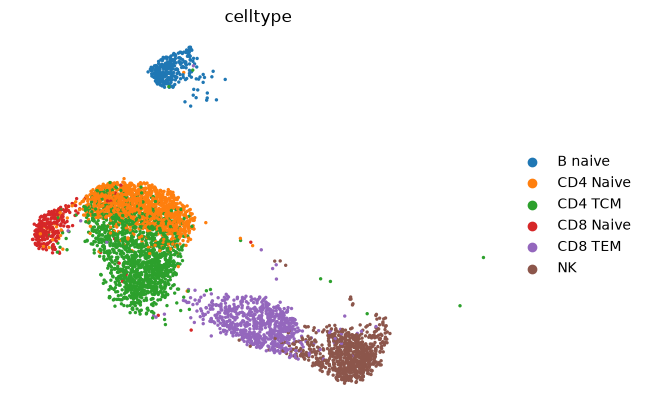

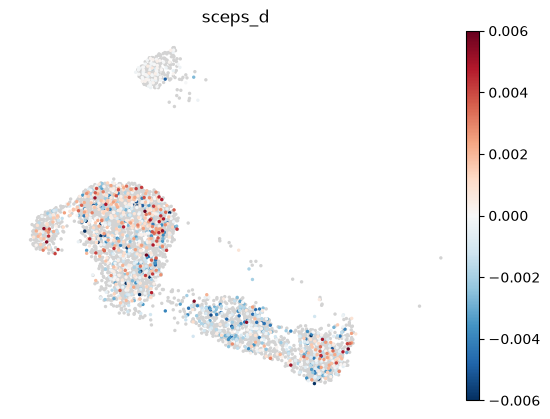

In [20]:
adata.obs["sceps_d"] = adata.obs.index.map(step1.set_index("CELL")["OMEGA_DIFF"])

sc.pl.umap(adata, color="celltype", frameon=False)
sc.pl.umap(
    adata, color="sceps_d", cmap="RdBu_r", vmin=-D_COLOR_LIMIT, vmax=D_COLOR_LIMIT, na_color="lightgrey", frameon=False
)

Grey cells are the neighborhoods `--sample-frac` did not select.

### Step 1.4 Scaling up

A real analysis sets `--sample-frac 1.0` and runs every cell neighborhood, which means
parallelizing. Here the index bounds are the right tool, because every slice gets analyzed:

```shell
# Option 1: let scEPS split the work evenly across N jobs (array job friendly)
sceps ... --total-num-job 100 --job-idx ${SLURM_ARRAY_TASK_ID} --out out/step1

# Option 2: pick the slices yourself, one job each
sceps ... --start-idx 0     --stop-idx 5000  --out out/step1
sceps ... --start-idx 5000  --stop-idx 10000 --out out/step1
```

Either way each job writes its own `step1.<start>-<stop>.*` shard, and Step 3 combines them
by glob. To time a run before committing to it, analyze one small slice with a *separate*
`--out` prefix and read `ELAPSED_TIME` from it. Keeping the prefix separate matters, or
Step 3's glob would count those neighborhoods twice.

Other options worth knowing when the run is too slow or too large:

| Option | Effect |
| --- | --- |
| `--use-analytical-stderr` | analytical instead of bootstrap standard errors; faster, at the cost of the bootstrap's robustness |
| `--cell-type-col` + `--focal-cell-type` | analyze one cell type at a time, e.g. one job per type |
| `--force-rerun` | recompute even when output exists |
| `--verbose` | per-neighborhood progress |

```{note}
If you split Step 1 by cell type, Step 2 must still be run **once across all cells**. The
blocks it defines are a property of the graph, not of any one analysis.
```

## Step 2. Approximately independent neighborhood blocks

Neighborhoods overlap: adjacent cells share cells and donors, so their $d$ statistics are
correlated. Averaging them in Step 3 with a naive bootstrap would treat those correlated
estimates as independent and understate the standard error.

`sceps-cluster-neighborhood` fixes this by mini-batch k-means clustering neighborhoods in
the embedding space, giving blocks of neighborhoods with similar donor composition. Step 3
then resamples **blocks** rather than individual neighborhoods.

Only the graph and the embedding are used, so this can run on a stripped-down `.h5ad` with
no `adata.X`. Two flags matter: `--neighbors-use-rep` names the embedding, the same
harmonized one the graph was built on, here `X_harmony` (the default is `X_pca_harmony`, the
name `misc/preprocess_scdata.py` produces). `--num-kmeans-cluster` sets the number of
blocks, whose default of 50 assumes far more cells than this subsample has.

In [21]:
!sceps-cluster-neighborhood \
    --adata {ADATA_PATH} \
    --donor-id-col donor_id \
    --neighbors-use-rep X_harmony \
    --num-kmeans-cluster {N_KMEANS_CLUSTERS} \
    --out {OUT_DIR}/step2

2026-11-14 23:04:03,179 - INFO - Loading single-cell data from work/sceps_input.h5ad
2026-11-14 23:04:03,329 - INFO - Identifying independent groups of cell neighborhoods


In [22]:
blocks = pd.read_table(OUT_DIR / "step2.txt.gz")
print(blocks.head())
print(f"\n{blocks.shape[0]:,} neighborhoods -> {blocks['sceps.neighborhood_cluster'].nunique()} blocks")
print("block sizes:", blocks["sceps.neighborhood_cluster"].value_counts().describe()[["min", "50%", "max"]].to_dict())

      sceps.cell_index  sceps.neighborhood_cluster
0  AACGTTGCAACGATCT-59                           7
1  AACTCCCCAGTTCATG-59                           7
2  AACTCTTTCACAAACC-59                          11
3  ACACCGGAGCTATGCT-59                           3
4  ACCTTTAGTAGAAAGG-59                           7

5,000 neighborhoods -> 20 blocks
block sizes: {'min': 26.0, '50%': 159.0, 'max': 809.0}


The mapping is keyed on `sceps.cell_index`, the cell identifier scEPS derived from
`adata.obs.index`, which is why leaving `--cell-id-col` unset everywhere keeps the steps
consistent.

## Step 3. Aggregate to cell types

`sceps-aggregate` averages $d$ across groups of neighborhoods and computes standard errors
by bootstrapping the blocks from Step 2. `--prefix` is a glob over the Step 1 shards, so a
sharded run is combined here. Run it once per grouping you care about:

In [23]:
# Per cell type
!sceps-aggregate \
    --prefix "{OUT_DIR}/step1.*.sceps.omega.txt.gz" \
    --adata {ADATA_PATH} \
    --neighborhood-clusters {OUT_DIR}/step2.txt.gz \
    --cell-type-col celltype \
    --out {OUT_DIR}/step3

# Across all analyzed neighborhoods (no --cell-type-col)
!sceps-aggregate \
    --prefix "{OUT_DIR}/step1.*.sceps.omega.txt.gz" \
    --adata {ADATA_PATH} \
    --neighborhood-clusters {OUT_DIR}/step2.txt.gz \
    --out {OUT_DIR}/step3

2026-11-14 23:04:09,853 - INFO - Loading single-cell data from work/sceps_input.h5ad
2026-11-14 23:04:10,007 - INFO - Using pre-computed clusters of cell neighborhoods from work/sceps_out/step2.txt.gz
2026-11-14 23:04:10,103 - INFO - Aggregating scEPS results across batches of runs
2026-11-14 23:04:10,104 - INFO - Found 8 scEPS score files
100%|███████████████████████████████████████████| 8/8 [00:00<00:00, 228.27it/s]
2026-11-14 23:04:10,141 - INFO - Testing at cell neighborhood level
2026-11-14 23:04:10,347 - INFO - Testing at cell type level celltype
100%|████████████████████████████████████████████| 6/6 [00:00<00:00,  6.25it/s]
2026-11-14 23:04:16,604 - INFO - Loading single-cell data from work/sceps_input.h5ad
2026-11-14 23:04:16,760 - INFO - Using pre-computed clusters of cell neighborhoods from work/sceps_out/step2.txt.gz
2026-11-14 23:04:16,861 - INFO - Aggregating scEPS results across batches of runs
2026-11-14 23:04:16,863 - INFO - Found 8 scEPS score files
100%|██████████████

Both runs also write `step3.sceps.omega.txt.gz`: the Step 1 shards concatenated, with
FDR-significance flags added across neighborhoods. Step 4 takes that file as its input.

The key columns mirror Step 1, one level up: `MEAN_OMEGA_DIFF` with `SE_`, `Z_` and `P_Z_`
prefixes. In addition, `NUM_SIGNIF_FDR{5,10,20}_OMEGA_DIFF` count how many *individual*
neighborhoods in the group were significant at each FDR threshold, useful for spotting a
cell type where a minority of neighborhoods carry the signal and the mean washes it out.

One thing to watch when only a slice of neighborhoods was analyzed: a cell type contributing
very few of them spans very few bootstrap blocks, so every bootstrap replicate can resample
the same handful and the standard error collapses toward zero, which shows up as an
enormous Z. That is arithmetic, not signal, so we drop those cell types rather than rank
them.

The neighborhood count we filter on (`MIN_NBHD_PER_CELLTYPE`) is only a proxy for that.
Here `B naive` passes with 73 neighborhoods, but they fall in just 2 of the 20 blocks, so its
standard error is several times smaller than the other types' and its Z of -4.3 is the same
arithmetic (a negative $d$ is not a hit in any case). Counting the blocks a cell type spans
is the stricter check.

In [24]:
print(sorted(p.name for p in OUT_DIR.glob("step3.*")))

cols = [
    "CELL_TYPE",
    "NUM_CELL",
    "MEAN_NUM_DONOR",
    "MEAN_OMEGA_DIFF",
    "SE_MEAN_OMEGA_DIFF",
    "Z_MEAN_OMEGA_DIFF",
    "P_Z_MEAN_OMEGA_DIFF",
]

by_celltype = pd.read_table(OUT_DIR / "step3.celltype.sceps.omega.celltype.txt")
overall = pd.read_table(OUT_DIR / "step3.sceps.omega.celltype.txt")

# How many analyzed neighborhoods each cell type actually contributed. NUM_CELL counts
# cells of that type, which is not the same thing when only a slice was analyzed.
analyzed = adata.obs.loc[step1["CELL"], "celltype"].value_counts()
by_celltype["N_NBHD"] = by_celltype["CELL_TYPE"].map(analyzed).fillna(0).astype(int)

thin = by_celltype[by_celltype["N_NBHD"] < MIN_NBHD_PER_CELLTYPE]
if not thin.empty:
    print(
        f"\ndropping {thin.shape[0]} cell type(s) with < {MIN_NBHD_PER_CELLTYPE} analyzed "
        f"neighborhoods, where the block bootstrap degenerates:"
    )
    print(thin[["CELL_TYPE", "N_NBHD", "SE_MEAN_OMEGA_DIFF", "Z_MEAN_OMEGA_DIFF"]].to_string(index=False))
by_celltype = by_celltype[by_celltype["N_NBHD"] >= MIN_NBHD_PER_CELLTYPE].reset_index(drop=True)

absent = sorted(set(adata.obs["celltype"].unique()) - set(by_celltype["CELL_TYPE"]) - set(thin["CELL_TYPE"]))
if absent:
    print(f"\nabsent from Step 3 entirely (no neighborhood passed scEPS QC): {', '.join(absent)}")

print("\n=== by cell type ===")
print(by_celltype[["N_NBHD", *cols]].sort_values("Z_MEAN_OMEGA_DIFF", ascending=False).to_string(index=False))
print("\n=== across all analyzed neighborhoods ===")
print(overall[cols].to_string(index=False))

['step3.celltype.sceps.omega.celltype.txt', 'step3.sceps.omega.celltype.txt', 'step3.sceps.omega.txt.gz']

=== by cell type ===
 N_NBHD CELL_TYPE  NUM_CELL  MEAN_NUM_DONOR  MEAN_OMEGA_DIFF  SE_MEAN_OMEGA_DIFF  Z_MEAN_OMEGA_DIFF  P_Z_MEAN_OMEGA_DIFF
     60 CD8 Naive        60          47.000         0.000789            0.000557            1.41830             0.156100
    309 CD4 Naive       309          54.841         0.000308            0.000323            0.95528             0.339430
    203        NK       203          45.650        -0.000248            0.000211           -1.17820             0.238720
    371   CD4 TCM       371          54.550        -0.000221            0.000154           -1.43930             0.150060
    200   CD8 TEM       200          44.960        -0.001540            0.000554           -2.78030             0.005431
     73   B naive        73          97.233        -0.000189            0.000044           -4.32900             0.000015

=== across all analyzed 

In [25]:
signif_cols = [
    "CELL_TYPE",
    "NUM_CELL",
    "NUM_SIGNIF_FDR5_OMEGA_DIFF",
    "NUM_SIGNIF_FDR10_OMEGA_DIFF",
    "NUM_SIGNIF_FDR20_OMEGA_DIFF",
]
by_celltype[signif_cols].sort_values("NUM_SIGNIF_FDR20_OMEGA_DIFF", ascending=False)

,CELL_TYPE,NUM_CELL,NUM_SIGNIF_FDR5_OMEGA_DIFF,NUM_SIGNIF_FDR10_OMEGA_DIFF,NUM_SIGNIF_FDR20_OMEGA_DIFF
0,CD8 TEM,200,0,0,0
1,CD4 TCM,371,0,0,0
2,CD4 Naive,309,0,0,0
3,NK,203,0,0,0
4,B naive,73,0,0,0
5,CD8 Naive,60,0,0,0


A forest plot of the per-cell-type estimates is usually the headline figure:

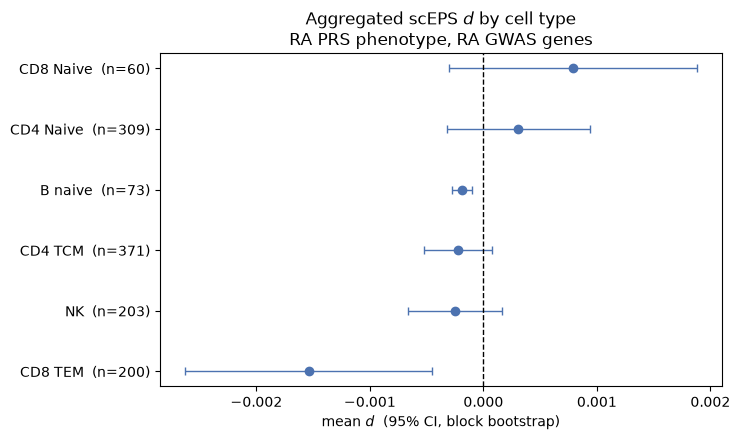

In [26]:
plot_df = by_celltype.sort_values("MEAN_OMEGA_DIFF")
y = np.arange(plot_df.shape[0])

fig, ax = plt.subplots(figsize=(7.5, 0.5 * plot_df.shape[0] + 1.5))
ax.errorbar(
    plot_df["MEAN_OMEGA_DIFF"],
    y,
    xerr=1.96 * plot_df["SE_MEAN_OMEGA_DIFF"],
    fmt="o",
    color="#4C72B0",
    ecolor="#4C72B0",
    capsize=3,
    lw=1,
)
ax.axvline(0, color="k", lw=1, ls="--")
ax.set_yticks(y)
ax.set_yticklabels([f"{ct}  (n={n:,})" for ct, n in zip(plot_df["CELL_TYPE"], plot_df["NUM_CELL"], strict=True)])
ax.set(
    xlabel="mean $d$  (95% CI, block bootstrap)",
    title="Aggregated scEPS $d$ by cell type\nRA PRS phenotype, RA GWAS genes",
)
plt.tight_layout()
plt.show()

Cell types whose interval sits clearly above zero are the candidate populations.

Other options for this step:

| Option | Effect |
| --- | --- |
| `--cell-type-col a,b,c` | aggregate at several resolutions at once, one output file each |
| `--use-inverse-variance-weights` | weight neighborhoods by precision instead of averaging equally |
| `--use-neighborhoods` | aggregate over an explicit list of cell IDs |
| `--add-column NAME VALUE` | stamp a constant column onto the output, handy when merging many runs |
| `--num-bootstrap` | bootstrap replicates (1,000 by default) |

Omitting `--neighborhood-clusters` falls back to an ordinary bootstrap over individual
neighborhoods, which will generally give standard errors that are too small.

## Step 4. Correlate d with gene expression

This step is optional. `sceps-corr` correlates each gene's expression with the scEPS
statistics across neighborhoods (Spearman by default), answering a follow-up question:
having found where the signal is, which genes mark those neighborhoods?

`--min-num-nonzero` drops genes expressed in too few cells. Note that it applies to the
neighborhoods actually analyzed, not the whole atlas, because `sceps-corr` intersects the
single-cell data with the scEPS result first. So on a subsampled run it has to come down
from its default of 100.

In [27]:
!sceps-corr \
    --adata {ADATA_PATH} \
    --sceps-result {OUT_DIR}/step3.sceps.omega.txt.gz \
    --min-num-nonzero {MIN_NUM_NONZERO} \
    --out {OUT_DIR}/step4

2026-11-14 23:04:23,043 - INFO - Loading scEPS results from work/sceps_out/step3.sceps.omega.txt.gz
100%|███████████████████████████████████| 12580/12580 [00:29<00:00, 431.01it/s]


In [28]:
step4 = pd.concat(
    [pd.read_table(p) for p in sorted(OUT_DIR.glob("step4.0-*.txt.gz"))],
    ignore_index=True,
).dropna(subset=["R_OMEGA_DIFF"])

# Map Ensembl IDs back to symbols for readability.
symbols = adata.var["feature_name"].astype(str).str.replace(r"_ENSG\d+$", "", regex=True)
step4["SYMBOL"] = step4["GENE"].map(symbols)

print(f"{step4.shape[0]:,} genes correlated\n")
show = ["SYMBOL", "GENE", "R_OMEGA_GWAS", "R_OMEGA_CONTROL", "R_OMEGA_DIFF"]
print("Most positively correlated with d:")
print(step4.nlargest(10, "R_OMEGA_DIFF")[show].to_string(index=False))
print("\nMost negatively correlated with d:")
print(step4.nsmallest(10, "R_OMEGA_DIFF")[show].to_string(index=False))

4,752 genes correlated

Most positively correlated with d:
    SYMBOL            GENE  R_OMEGA_GWAS  R_OMEGA_CONTROL  R_OMEGA_DIFF
     MEF2C ENSG00000081189      0.270664        -0.348488      0.422498
      RIT1 ENSG00000143622      0.291187        -0.263607      0.358584
      MMAB ENSG00000139428      0.174342        -0.355523      0.340620
     TCL1A ENSG00000100721      0.087446        -0.153319      0.317677
     CEPT1 ENSG00000134255      0.181212        -0.250336      0.308276
    MTHFD2 ENSG00000065911      0.127084        -0.321188      0.287123
      CUL5 ENSG00000166266      0.165872        -0.189418      0.287118
     KDM2B ENSG00000089094      0.250361        -0.270707      0.274315
     LTBP3 ENSG00000168056      0.151590        -0.119627      0.265625
CEP250-AS1 ENSG00000230155      0.120806        -0.204218      0.255272

Most negatively correlated with d:
SYMBOL            GENE  R_OMEGA_GWAS  R_OMEGA_CONTROL  R_OMEGA_DIFF
 VPS16 ENSG00000215305     -0.448932         

The same restricted to one cell type, via `--cell-type-col` / `--focal-cell-type`. With
fewer neighborhoods in a single cell type, `--min-num-nonzero` has to come down further.
Otherwise every gene is filtered out and the tool has nothing to concatenate.

In [29]:
focal = by_celltype.sort_values("Z_MEAN_OMEGA_DIFF", ascending=False)["CELL_TYPE"].iloc[0]
n_focal = int((adata.obs.loc[step1["CELL"], "celltype"] == focal).sum())
focal_min_nonzero = max(5, n_focal // 10)
print(f"focal cell type: {focal} ({n_focal} analyzed neighborhoods) " f"-> --min-num-nonzero {focal_min_nonzero}")

focal cell type: CD8 Naive (60 analyzed neighborhoods) -> --min-num-nonzero 6


In [30]:
!sceps-corr \
    --adata {ADATA_PATH} \
    --sceps-result {OUT_DIR}/step3.sceps.omega.txt.gz \
    --cell-type-col celltype \
    --focal-cell-type "{focal}" \
    --min-num-nonzero {focal_min_nonzero} \
    --out {OUT_DIR}/step4_focal

2026-11-14 23:04:57,787 - INFO - Loading scEPS results from work/sceps_out/step3.sceps.omega.txt.gz
100%|██████████████████████████████████| 12580/12580 [00:07<00:00, 1762.19it/s]


In [31]:
step4_focal = pd.concat(
    [pd.read_table(p) for p in sorted(OUT_DIR.glob("step4_focal.*.txt.gz"))],
    ignore_index=True,
).dropna(subset=["R_OMEGA_DIFF"])
step4_focal["SYMBOL"] = step4_focal["GENE"].map(symbols)

print(f"{step4_focal.shape[0]:,} genes correlated within {focal}")
step4_focal.nlargest(10, "R_OMEGA_DIFF")[["SYMBOL", "GENE", "R_OMEGA_GWAS", "R_OMEGA_CONTROL", "R_OMEGA_DIFF"]]

2,496 genes correlated within CD8 Naive


,SYMBOL,GENE,R_OMEGA_GWAS,R_OMEGA_CONTROL,R_OMEGA_DIFF
197,IFI16,ENSG00000163565,0.485714,-0.600000,0.942857
396,NFE2L2,ENSG00000116044,0.857143,-0.761905,0.928571
222,TOR1AIP2,ENSG00000169905,0.142857,-0.357143,0.892857
1348,TMEM109,ENSG00000110108,0.942857,-0.371429,0.885714
2356,CHMP4B,ENSG00000101421,0.314286,-0.885714,0.885714
509,APPL1,ENSG00000157500,0.428571,-0.142857,0.857143
1261,NUTM2B-AS1,ENSG00000225484,0.371429,-0.542857,0.828571
1494,SINHCAF,ENSG00000139146,0.485714,-0.257143,0.828571
419,CYP20A1,ENSG00000119004,0.464286,-0.142857,0.821429
711,UQCRQ,ENSG00000164405,0.351648,-0.505495,0.802198


```{warning}
By default `sceps-corr` reports correlations with **no** test statistics, deliberately: both
the scEPS statistics and gene expression are correlated across neighborhoods, which makes a
valid test hard to construct. Adding `--num-bootstrap 1000 --neighborhood-clusters
<step2 output>` produces `SE_`, `Z_` and `P_` columns via block bootstrap, but treat those
p-values as descriptive rather than calibrated.
```

## Summary and what changes for a real study

The whole workflow, as four commands:

```shell
# Step 1. Per-neighborhood statistics (parallelize over --job-idx)
sceps \
    --adata harmonized.h5ad \
    --donor-id-col donor_id \
    --gene-list magma_RA.genes.out \
    --auto-gene-selection \
    --pheno ra_prs \
    --scale-pheno --scale-pheno-neighborhood \
    --covar "age,sex,sceps.prop_cells_local" \
    --total-num-job 100 --job-idx ${SLURM_ARRAY_TASK_ID} \
    --out out/step1

# Step 2. Approximately independent blocks (once, across ALL cells)
sceps-cluster-neighborhood \
    --adata harmonized.noX.h5ad \
    --donor-id-col donor_id \
    --neighbors-use-rep X_harmony \
    --out out/step2

# Step 3. Aggregate to cell types
sceps-aggregate \
    --prefix "out/step1.*.sceps.omega.txt.gz" \
    --adata harmonized.noX.h5ad \
    --neighborhood-clusters out/step2.txt.gz \
    --cell-type-col celltype \
    --out out/step3

# Step 4. Correlate with gene expression (optional)
sceps-corr \
    --adata harmonized.h5ad \
    --sceps-result out/step3.sceps.omega.txt.gz \
    --out out/step4
```

The wiki suggests one directory per step, which keeps the globs in Steps 3 and 4 simple:

```text
DISEASE/
├── step_0a/out/     # MAGMA gene-level statistics
├── step_0b/out/     # phenotype (PRS, or real disease status)
├── step_0c/out/     # harmonized .h5ad files
├── step1/out/       # one shard per parallel job
├── step2/out/
├── step3/out/
└── step4/out/
```

### Checklist for real data

- **The full cohort** via `get_onek1k()` rather than `get_dummy_onek1k()`, whose genotypes
  are chromosome 22 plus a 0.1% sample of the rest. It returns the same `DonorData` layout,
  so the cells above run unchanged; the download is ~20 GB, and PLINK must be on `PATH`
  for the one-off conversion of the VCF.
- **A measured phenotype** when you have one, such as case/control status or a quantitative trait
  in the same donors. scEPS dummy-codes a two-level phenotype automatically. If it lives
  outside the `.h5ad`, pass it with `--pheno-file` (a table keyed by the same donor ID
  column) rather than merging it in by hand.
- **Check the gene identifiers match** `adata.var_names`. A mismatch yields an empty gene
  set, not an error.
- **Harmonize before building the graph**, and point `--neighbors-use-rep` at the harmonized
  embedding.
- **Donor-level covariates** in `--covar`, and keep `sceps.prop_cells_local` in the list.
  Genotype PCs for ancestry adjustment ship with both datasets in `dd.D.obsm["gPCs"]`.
- **All cells**, via `--total-num-job` / `--job-idx` as an array job.
- **Bootstrap standard errors** (the default). Reach for `--use-analytical-stderr` only when
  compute is the binding constraint.
- **Interpret the sign**: a hit needs $d > 0$ *and* $\omega^2_{gwas} > 0$.

See the [wiki](https://github.com/Genentech/sceps/wiki) for the full option reference, and
the [preprint](https://www.medrxiv.org/content/10.64898/2026.06.26.26356714v1) for the
method.